Write a program to perform the following operations on images and videos:
a.	Read, display, and write an image.

In [1]:
!pip install opencv-python matplotlib

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import cv2
import matplotlib.pyplot as plt

In [3]:
img = cv2.imread("Me.png")

In [4]:
print(type(img))
print(img.shape)

<class 'numpy.ndarray'>
(235, 253, 3)


OpenCV reads images in BGR order, so we convert to RGB before showing it with matplotlib.

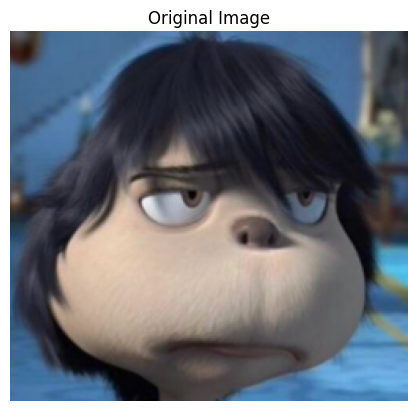

In [5]:
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

Writing the image to disk.

In [6]:
cv2.imwrite("output.png", img)

True

b.	Convert the image into different formats (PNG, TIFF, and many more).

In [7]:
cv2.imwrite("converted.png", img)
cv2.imwrite("converted.tiff", img)
cv2.imwrite("converted.jpg", img)
cv2.imwrite("converted.bmp", img)
cv2.imwrite("converted.webp", img)

True

In [8]:
import os

for f in ["converted.png", "converted.tiff", "converted.jpg", "converted.bmp", "converted.webp"]:
    print(f, "->", os.path.getsize(f), "bytes")

converted.png -> 90960 bytes
converted.tiff -> 95042 bytes
converted.jpg -> 18140 bytes
converted.bmp -> 178654 bytes
converted.webp -> 52738 bytes


Reading one of the converted files back to confirm the conversion worked.

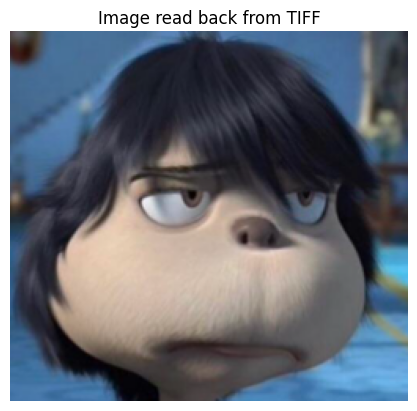

In [9]:
tiff_img = cv2.imread("converted.tiff")
plt.imshow(cv2.cvtColor(tiff_img, cv2.COLOR_BGR2RGB))
plt.title("Image read back from TIFF")
plt.axis("off")
plt.show()

c.	Perform image resizing.

In [10]:
h, w = img.shape[:2]
print("Original size:", w, "x", h)

Original size: 253 x 235


New size: 300 x 200


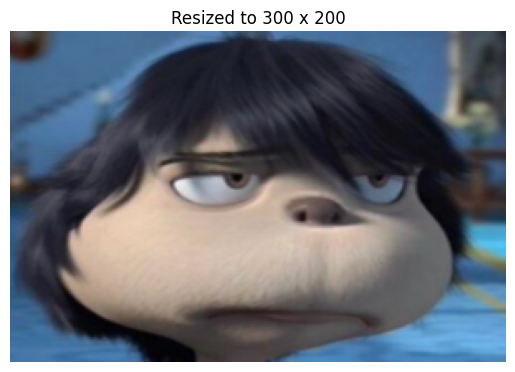

In [11]:
resized = cv2.resize(img, (300, 200))
print("New size:", resized.shape[1], "x", resized.shape[0])

plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title("Resized to 300 x 200")
plt.axis("off")
plt.show()

Resizing by a scale factor keeps the aspect ratio intact.

Half: (118, 126, 3)
Double: (470, 506, 3)


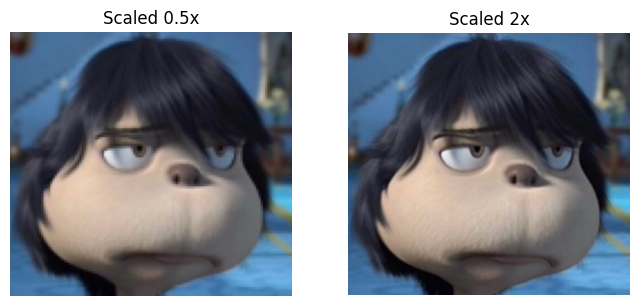

In [12]:
half = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
double = cv2.resize(img, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)

print("Half:", half.shape)
print("Double:", double.shape)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(half, cv2.COLOR_BGR2RGB))
plt.title("Scaled 0.5x")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(double, cv2.COLOR_BGR2RGB))
plt.title("Scaled 2x")
plt.axis("off")
plt.show()

In [13]:
cv2.imwrite("resized.png", resized)

True

d.	Convert a colored image into a grayscale image.

In [14]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Colour shape:", img.shape)
print("Gray shape:", gray.shape)

Colour shape: (235, 253, 3)
Gray shape: (235, 253)


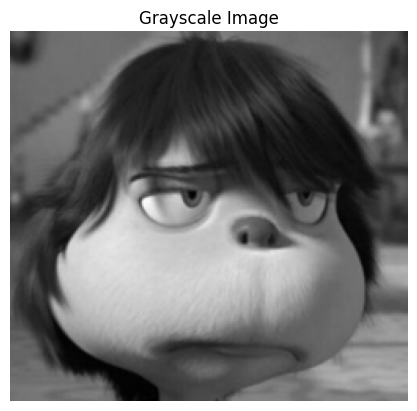

In [15]:
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

The same thing can be done directly while reading the file, by passing a flag to `cv2.imread`.

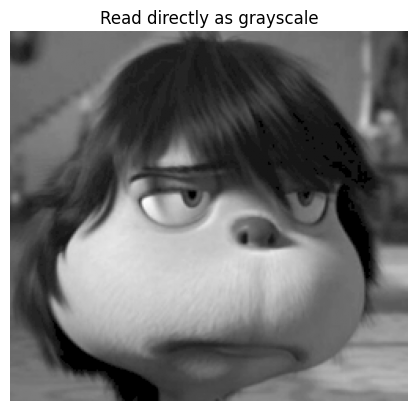

In [16]:
gray2 = cv2.imread("Me.png", cv2.IMREAD_GRAYSCALE)
plt.imshow(gray2, cmap="gray")
plt.title("Read directly as grayscale")
plt.axis("off")
plt.show()

In [17]:
cv2.imwrite("grayscale.png", gray)

True

e.	Read and display a video.

In [18]:
cap = cv2.VideoCapture("vid_assign_1mp4.mp4")
print("Opened:", cap.isOpened())

Opened: True


A video is just a sequence of frames, so first we look at its basic properties.

In [19]:
fps = cap.get(cv2.CAP_PROP_FPS)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("FPS:", fps)
print("Total frames:", total)
print("Resolution:", width, "x", height)
print("Duration (s):", round(total / fps, 2))

FPS: 29.97002997002997
Total frames: 99
Resolution: 640 x 480
Duration (s): 3.3


Reading the video frame by frame with `cap.read()`. It returns `False` once the video ends.

In [20]:
cap = cv2.VideoCapture("vid_assign_1mp4.mp4")

count = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break
    count += 1

cap.release()
print("Frames read:", count)

Frames read: 99


In a normal Python script the video is displayed with `cv2.imshow()` inside the loop:

```python
cap = cv2.VideoCapture("vid_assign_1mp4.mp4")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    cv2.imshow("Video", frame)
    if cv2.waitKey(25) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()
```

That opens a separate GUI window, which does not render inside a notebook, so here we display the frames with matplotlib instead.

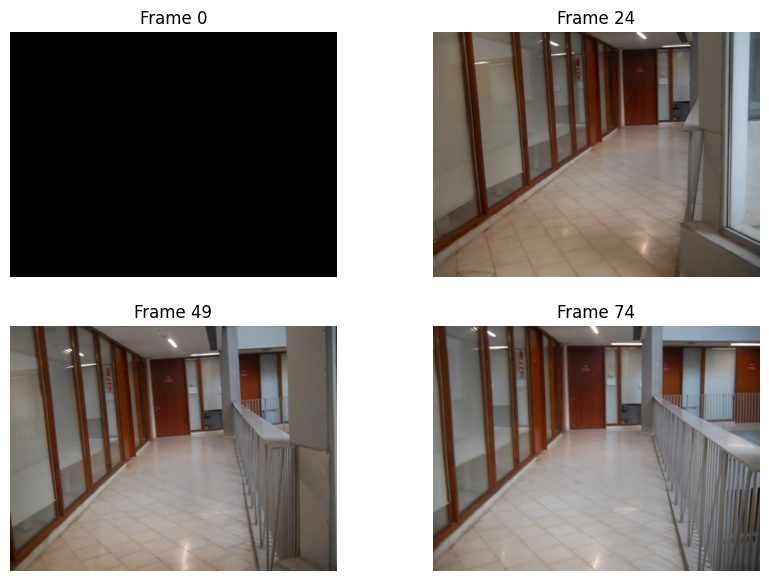

In [21]:
cap = cv2.VideoCapture("vid_assign_1mp4.mp4")

frames_to_show = [0, total // 4, total // 2, (3 * total) // 4]
plt.figure(figsize=(10, 7))

for i, pos in enumerate(frames_to_show):
    cap.set(cv2.CAP_PROP_POS_FRAMES, pos)
    ret, frame = cap.read()
    if ret:
        plt.subplot(2, 2, i + 1)
        plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        plt.title("Frame " + str(pos))
        plt.axis("off")

cap.release()
plt.show()

f.	Extract frames from a video.

In [22]:
import os

os.makedirs("frames", exist_ok=True)

cap = cv2.VideoCapture("vid_assign_1mp4.mp4")
count = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break
    cv2.imwrite("frames/frame_" + str(count) + ".jpg", frame)
    count += 1

cap.release()
print("Extracted", count, "frames into the folder frames/")

Extracted 99 frames into the folder frames/


In [23]:
print(sorted(os.listdir("frames"))[:10])

['frame_0.jpg', 'frame_1.jpg', 'frame_10.jpg', 'frame_11.jpg', 'frame_12.jpg', 'frame_13.jpg', 'frame_14.jpg', 'frame_15.jpg', 'frame_16.jpg', 'frame_17.jpg']


Displaying a few of the saved frames to verify the extraction.

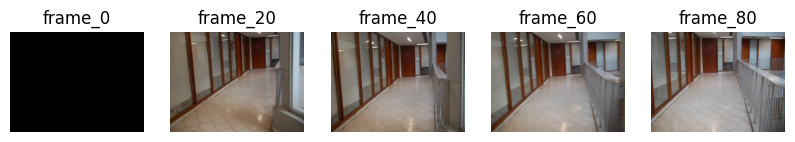

In [24]:
plt.figure(figsize=(10, 4))

for i, n in enumerate([0, 20, 40, 60, 80]):
    f = cv2.imread("frames/frame_" + str(n) + ".jpg")
    plt.subplot(1, 5, i + 1)
    plt.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    plt.title("frame_" + str(n))
    plt.axis("off")

plt.show()

Often we do not need every single frame. Here we save only one frame per second.

In [25]:
os.makedirs("frames_1fps", exist_ok=True)

cap = cv2.VideoCapture("vid_assign_1mp4.mp4")
step = int(round(fps))
i = 0
saved = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break
    if i % step == 0:
        cv2.imwrite("frames_1fps/sec_" + str(saved) + ".jpg", frame)
        saved += 1
    i += 1

cap.release()
print("Saved", saved, "frames (1 per second)")

Saved 4 frames (1 per second)
